# 04 · Train and compare enrollment models
**Prerequisite:** run [03_feature_reduction.ipynb](03_feature_reduction.ipynb) with the default 15-feature selection.

We train three versions on the same rows: the selected 15 predictors, those predictors plus acceptance fee, and those predictors plus acceptance fee and deposit fields. Every version saves its model, complete metrics JSON, and test predictions in **results/**. The first version corresponds to **no_acceptance_fee_no_deposits_metrics.json**.

The acceptance-fee and deposit variants use later-stage information. Their results apply only when those fields are available at prediction time. Higher scores with those fields do not establish better early-stage predictions.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Open the notebook from the project folder. All paths are relative to it.
BASE_DIR = Path.cwd()
if not (BASE_DIR / "datathon-dataset-2026.xlsx").exists():
    raise FileNotFoundError("Open this notebook with the datathon project folder as the working directory.")
print(f"Project folder: {BASE_DIR}")
import json
from time import perf_counter

import joblib
import numpy as np
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from threadpoolctl import threadpool_limits

def stratified_split(target, test_fraction=0.2, seed=42):
    """Create reproducible positional splits without another ML dependency."""
    rng = np.random.default_rng(seed)
    train, test = [], []
    for label in (0, 1):
        positions = np.flatnonzero(target.to_numpy() == label)
        if len(positions) < 2:
            raise ValueError("Each enrollment class needs at least two labeled rows.")
        rng.shuffle(positions)
        test_count = min(len(positions) - 1, max(1, round(len(positions) * test_fraction)))
        test.extend(positions[:test_count])
        train.extend(positions[test_count:])
    return np.sort(train), np.sort(test)

BASE_DIR = Path.cwd()
# cleaner.py encodes missing values in these nominal fields as -1.
FACTORIZED_COLUMNS = {"app_fee", "acceptance_fee", "residency", "sex", "college"}
DEPOSIT_FEATURES = ["deposit_dt", "deposit_mo", "deposit_yr", "deposited"]
MODEL_VARIANTS = {
    "no_acceptance_fee_no_deposits": [],
    "with_acceptance_fee_no_deposits": ["acceptance_fee"],
    "with_acceptance_fee_and_deposits": ["acceptance_fee", *DEPOSIT_FEATURES],
}



import matplotlib.pyplot as plt
summary_path = BASE_DIR / "feature_reduction_output" / "selection_summary.json"
output_dir = BASE_DIR / "results"
threshold = 0.5
if not 0 < threshold < 1:
    raise ValueError("threshold must be between 0 and 1")
reports = {}
print(f"Classification cutoff: {threshold}; outputs: {output_dir}")


Project folder: c:\Users\Grcar\Documents\datathon
Classification cutoff: 0.5; outputs: c:\Users\Grcar\Documents\datathon\results


## 1. Define data checks, preprocessing, and evaluation
The model uses small gradient-boosted trees. Nominal category codes are treated as categories; missing numeric values and unknown categories are handled by the model. The saved pipeline includes preprocessing. All preprocessing is fitted on training data.


In [2]:
def read_table(path):
    """Read the same cleaned numeric representation used for feature selection."""
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    if path.suffix.lower() in {".xlsx", ".xlsm"}:
        return pd.read_excel(path)
    raise ValueError(f"Expected a CSV or XLSX file, received: {path}")

def prepare_features(frame, features):
    """Enforce feature order and normalize missing values for training/inference."""
    missing = [name for name in features if name not in frame.columns]
    if missing:
        raise ValueError(f"Missing selected feature columns: {', '.join(missing)}")
    if frame.empty:
        raise ValueError("The input contains no rows.")
    values = frame.loc[:, features].apply(pd.to_numeric, errors="raise").astype(float)
    values = values.replace([np.inf, -np.inf], np.nan)
    for name in FACTORIZED_COLUMNS.intersection(features):
        values[name] = values[name].mask(values[name].eq(-1))
    return values

def load_selection(path):
    summary = json.loads(path.read_text(encoding="utf-8"))
    features = summary.get("selected_features")
    target = summary.get("target")
    if (
        not isinstance(features, list)
        or not features
        or not all(isinstance(name, str) and name for name in features)
        or len(features) != len(set(features))
    ):
        raise ValueError("The selection summary must have unique selected_features.")
    if not isinstance(target, str) or not target:
        raise ValueError("The selection summary must specify a target column.")
    forbidden = set(summary.get("excluded_columns", {})) | {target}
    if forbidden.intersection(features):
        raise ValueError("Selected features contain the target or excluded columns.")
    return summary, features, target

def load_split(frame, features, target):
    if target not in frame:
        raise ValueError(f"Missing target column '{target}' in split.")
    labels = pd.to_numeric(frame[target], errors="raise")
    if labels.isna().any() or not labels.isin([0, 1]).all() or labels.nunique() != 2:
        raise ValueError("Each split must contain both classes, encoded as 0 and 1.")
    return frame, prepare_features(frame, features), labels.astype(int)

def prepare_splits(summary_path, input_path=None):
    """Recover additional columns only after verifying the feature-selection rows."""
    summary, original_features, target = load_selection(summary_path)
    if len(original_features) != 15:
        raise ValueError("Expected the original top 15 features; rerun feature_reduction.py with --top-k 15.")
    if set(original_features).intersection(["acceptance_fee", *DEPOSIT_FEATURES]):
        raise ValueError("The original 15 features must exclude acceptance_fee and deposit columns.")
    source = input_path if input_path is not None else Path(summary["input"])
    print(f"Reading {source} ...", flush=True)
    dataset = read_table(source)
    required = original_features + ["acceptance_fee", *DEPOSIT_FEATURES, target]
    missing = [name for name in required if name not in dataset]
    if missing:
        raise ValueError(f"Missing source columns: {', '.join(missing)}")
    if not dataset[target].dropna().isin([0, 1]).all():
        raise ValueError(f"'{target}' must contain only 0, 1, or missing values.")
    labeled = dataset.dropna(subset=[target]).reset_index(drop=True)
    train_positions, test_positions = stratified_split(labeled[target])
    splits = {
        "train": labeled.iloc[train_positions].reset_index(drop=True),
        "test": labeled.iloc[test_positions].reset_index(drop=True),
    }
    for name, frame in splits.items():
        original = read_table(summary_path.parent / f"reduced_{name}.csv")
        try:
            pd.testing.assert_frame_equal(
                frame[original_features + [target]],
                original[original_features + [target]],
                check_dtype=False,
            )
        except AssertionError as error:
            raise ValueError(
                f"Reconstructed {name} rows do not match the original split. "
                "Use the same cleaned source data used for feature reduction."
            ) from error
        if summary.get(f"{name}_rows", len(frame)) != len(frame):
            raise ValueError(f"{name}_rows does not match the selection summary; regenerate the split.")
    return summary, original_features, target, splits

def build_model(features):
    """Small boosted trees capture nonlinear effects without scaling/imputation.

    Nominal codes are encoded as categorical features, without imposing an order.
    Unknown categories become missing, which the classifier handles natively.
    The encoder and classifier are saved together to preserve inference behavior.
    """
    categorical = [name for name in features if name in FACTORIZED_COLUMNS]
    numeric = [name for name in features if name not in categorical]
    transformers = [("numeric", "passthrough", numeric)]
    if categorical:
        transformers.append((
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=np.nan,
                encoded_missing_value=np.nan,
            ),
            categorical,
        ))
    return Pipeline([
        ("features", ColumnTransformer(transformers)),
        ("classifier", HistGradientBoostingClassifier(
            categorical_features=[False] * len(numeric) + [True] * len(categorical),
            learning_rate=0.1,
            max_iter=150,
            max_leaf_nodes=15,
            min_samples_leaf=30,
            l2_regularization=1.0,
            early_stopping=True,
            validation_fraction=0.1,
            random_state=42,
        )),
    ])

def evaluate(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predictions)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(labels, probabilities)),
        "average_precision": float(average_precision_score(labels, probabilities)),
        "log_loss": float(log_loss(labels, probabilities, labels=[0, 1])),
        "brier_score": float(brier_score_loss(labels, probabilities)),
        "confusion_matrix": confusion_matrix(labels, predictions, labels=[0, 1]).tolist(),
    }

def save_predictions(frame, probabilities, threshold, output, target):
    # Row numbers are one-based data-row positions (excluding the header).
    result = pd.DataFrame({"row_number": np.arange(1, len(frame) + 1)})
    if "student_id" in frame:
        result["student_id"] = frame["student_id"].to_numpy()
    if target in frame:
        result[f"actual_{target}"] = frame[target].to_numpy()
    result["enrollment_probability"] = probabilities
    result["predicted_enrolled"] = (probabilities >= threshold).astype(int)
    output.parent.mkdir(parents=True, exist_ok=True)
    result.to_csv(output, index=False)
print("Data checks, model builder, and evaluation helpers are ready.")


Data checks, model builder, and evaluation helpers are ready.


## 2. Recover and verify the original split
Reconstruct the seed-42 split from the cleaned source, then compare it with the saved reduced train and test files. A mismatch stops execution so all variants use the same rows.


In [3]:
summary, original_features, target, splits = prepare_splits(summary_path, BASE_DIR / "cleaned_dataset.xlsx")
display(pd.DataFrame({"split": list(splits), "rows": [len(frame) for frame in splits.values()], "enrollment_rate": [frame[target].mean() for frame in splits.values()]}))
display(pd.DataFrame({"original_selected_feature": original_features}))


Reading c:\Users\Grcar\Documents\datathon\cleaned_dataset.xlsx ...


,split,rows,enrollment_rate
0,train,55633,0.330775
1,test,13908,0.330745


,original_selected_feature
0,visit_mo
1,campus_visit_tot
2,visit_yr
3,visit_dt
4,act_cmpst
5,act_engl
6,act_math
7,admitted
8,residency
9,miles_from_campus


## 3. Train and evaluate each version
At a cutoff of 0.5, probabilities of at least 0.5 count as predicted enrollment. Precision measures how often predicted enrollees enroll; recall measures how many actual enrollees we find. ROC AUC measures ranking across cutoffs. The prior baseline predicts the training enrollment rate for everyone. No model settings are tuned against these test results.


### A · Original 15 predictors
Output prefix: **no_acceptance_fee_no_deposits**.


In [4]:
variant = 'no_acceptance_fee_no_deposits'
additional_features = MODEL_VARIANTS[variant]
features = original_features + additional_features
_, training, train_labels = load_split(splits["train"], features, target)
test_frame, testing, test_labels = load_split(splits["test"], features, target)
model_path = output_dir / f"{variant}_model.joblib"


display(pd.DataFrame({"model_feature": features}))
print(f"Training shape: {training.shape}; test shape: {testing.shape}")


,model_feature
0,visit_mo
1,campus_visit_tot
2,visit_yr
3,visit_dt
4,act_cmpst
5,act_engl
6,act_math
7,admitted
8,residency
9,miles_from_campus


Training shape: (55633, 15); test shape: (13908, 15)


#### Fit on training rows
Early stopping uses an internal validation subset of the training data. The held-out test data is used after fitting.


In [5]:
model = build_model(features)
started = perf_counter()
# A small thread pool avoids parallelism overhead on this modest dataset.
with threadpool_limits(limits=2):
    model.fit(training, train_labels)
    fit_seconds = perf_counter() - started
    probabilities = model.predict_proba(testing)[:, 1]

print(f"Fitted {model.named_steps['classifier'].n_iter_} boosting iterations in {fit_seconds:.2f}s")
display(pd.Series(probabilities, name="test_enrollment_probability").describe().to_frame())


Fitted 150 boosting iterations in 1.35s


,test_enrollment_probability
count,13908.000000
mean,0.330369
std,0.276433
min,0.000057
25%,0.070144
50%,0.256171
75%,0.583341
max,0.965583


#### Evaluate on the held-out test rows
Rows in the confusion matrix are actual outcomes; columns are predictions. Zero means not enrolled and one means enrolled.


In [6]:
baseline = DummyClassifier(strategy="prior").fit(training, train_labels)
baseline_probabilities = baseline.predict_proba(testing)[:, 1]
metrics = evaluate(test_labels, probabilities, threshold)
report = {
    "variant": variant,
    "original_selected_features": original_features,
    "additional_features": additional_features,
    "model": "HistGradientBoostingClassifier",
    "scikit_learn_version": sklearn.__version__,
    "selected_features": features,
    "target": target,
    "train_rows": len(training),
    "test_rows": len(testing),
    "train_enrollment_rate": float(train_labels.mean()),
    "test_enrollment_rate": float(test_labels.mean()),
    "threshold": threshold,
    "fit_seconds": fit_seconds,
    "boosting_iterations": int(model.named_steps["classifier"].n_iter_),
    "test_metrics": metrics,
    "prior_baseline_metrics": evaluate(test_labels, baseline_probabilities, threshold),
    "confusion_matrix_layout": "Rows = actual [0, 1]; columns = predicted [0, 1].",
    "selection_summary": str(summary_path.resolve()),
    "split": summary.get("split"),
    "prediction_time_assumption": (
        "All selected fields must be available at prediction time. "
        f"Acceptance fee included: {'acceptance_fee' in features}; "
        f"deposit status and dates included: {'deposited' in features}."
    ),
    "evaluation_note": (
        "Feature selection and preprocessing use training rows only. Early stopping "
        "uses an internal training-data validation split. The original test set is "
        "used only for final evaluation; these metrics do not measure future-cohort "
        "performance. All predictors must be available at prediction time."
    ),
}

reports[variant] = report
display(pd.DataFrame({"model": {k: v for k, v in metrics.items() if k != "confusion_matrix"}, "prior_baseline": {k: v for k, v in report["prior_baseline_metrics"].items() if k != "confusion_matrix"}}))
display(pd.DataFrame(metrics["confusion_matrix"], index=["Actual: not enrolled", "Actual: enrolled"], columns=["Predicted: not enrolled", "Predicted: enrolled"]))


,model,prior_baseline
accuracy,0.788395,0.669255
balanced_accuracy,0.763346,0.500000
precision,0.676841,0.000000
recall,0.689348,0.000000
f1,0.683037,0.000000
roc_auc,0.861883,0.500000
average_precision,0.722304,0.330745
log_loss,0.426737,0.634705
brier_score,0.140920,0.221353


,Predicted: not enrolled,Predicted: enrolled
Actual: not enrolled,7794,1514
Actual: enrolled,1429,3171


#### Save the fitted pipeline, metrics, and predictions
The preview shows the same predictions written to CSV; probabilities describe the model estimate, not a guaranteed outcome.


In [7]:
output_dir.mkdir(parents=True, exist_ok=True)
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "variant": variant,
    "model": model,
    "selected_features": features,
    "target": target,
    "threshold": threshold,
    "scikit_learn_version": sklearn.__version__,
}, model_path)
(output_dir / f"{variant}_metrics.json").write_text(
    json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
save_predictions(test_frame, probabilities, threshold, output_dir / f"{variant}_test_predictions.csv", target)

display(pd.read_csv(output_dir / f"{variant}_test_predictions.csv").head(10))
display(pd.DataFrame({"saved_file": [model_path.name, f"{variant}_metrics.json", f"{variant}_test_predictions.csv"]}))


,row_number,student_id,actual_enrolled,enrollment_probability,predicted_enrolled
0,1,112761,0,0.000264,0
1,2,108208,0,0.000220,0
2,3,47814,0,0.000492,0
3,4,91551,0,0.000369,0
4,5,95105,0,0.000366,0
5,6,106273,0,0.000408,0
6,7,107016,0,0.000295,0
7,8,96524,0,0.000380,0
8,9,108469,0,0.000218,0
9,10,94348,0,0.000230,0


,saved_file
0,no_acceptance_fee_no_deposits_model.joblib
1,no_acceptance_fee_no_deposits_metrics.json
2,no_acceptance_fee_no_deposits_test_predictions...


### B · Add acceptance fee
Output prefix: **with_acceptance_fee_no_deposits**.


In [8]:
variant = 'with_acceptance_fee_no_deposits'
additional_features = MODEL_VARIANTS[variant]
features = original_features + additional_features
_, training, train_labels = load_split(splits["train"], features, target)
test_frame, testing, test_labels = load_split(splits["test"], features, target)
model_path = output_dir / f"{variant}_model.joblib"


display(pd.DataFrame({"model_feature": features}))
print(f"Training shape: {training.shape}; test shape: {testing.shape}")


,model_feature
0,visit_mo
1,campus_visit_tot
2,visit_yr
3,visit_dt
4,act_cmpst
5,act_engl
6,act_math
7,admitted
8,residency
9,miles_from_campus


Training shape: (55633, 16); test shape: (13908, 16)


#### Fit on training rows
Early stopping uses an internal validation subset of the training data. The held-out test data is used after fitting.


In [9]:
model = build_model(features)
started = perf_counter()
# A small thread pool avoids parallelism overhead on this modest dataset.
with threadpool_limits(limits=2):
    model.fit(training, train_labels)
    fit_seconds = perf_counter() - started
    probabilities = model.predict_proba(testing)[:, 1]

print(f"Fitted {model.named_steps['classifier'].n_iter_} boosting iterations in {fit_seconds:.2f}s")
display(pd.Series(probabilities, name="test_enrollment_probability").describe().to_frame())


Fitted 93 boosting iterations in 0.88s


,test_enrollment_probability
count,13908.000000
mean,0.331017
std,0.431815
min,0.000029
25%,0.000987
50%,0.002324
75%,0.875472
max,0.993589


#### Evaluate on the held-out test rows
Rows in the confusion matrix are actual outcomes; columns are predictions. Zero means not enrolled and one means enrolled.


In [10]:
baseline = DummyClassifier(strategy="prior").fit(training, train_labels)
baseline_probabilities = baseline.predict_proba(testing)[:, 1]
metrics = evaluate(test_labels, probabilities, threshold)
report = {
    "variant": variant,
    "original_selected_features": original_features,
    "additional_features": additional_features,
    "model": "HistGradientBoostingClassifier",
    "scikit_learn_version": sklearn.__version__,
    "selected_features": features,
    "target": target,
    "train_rows": len(training),
    "test_rows": len(testing),
    "train_enrollment_rate": float(train_labels.mean()),
    "test_enrollment_rate": float(test_labels.mean()),
    "threshold": threshold,
    "fit_seconds": fit_seconds,
    "boosting_iterations": int(model.named_steps["classifier"].n_iter_),
    "test_metrics": metrics,
    "prior_baseline_metrics": evaluate(test_labels, baseline_probabilities, threshold),
    "confusion_matrix_layout": "Rows = actual [0, 1]; columns = predicted [0, 1].",
    "selection_summary": str(summary_path.resolve()),
    "split": summary.get("split"),
    "prediction_time_assumption": (
        "All selected fields must be available at prediction time. "
        f"Acceptance fee included: {'acceptance_fee' in features}; "
        f"deposit status and dates included: {'deposited' in features}."
    ),
    "evaluation_note": (
        "Feature selection and preprocessing use training rows only. Early stopping "
        "uses an internal training-data validation split. The original test set is "
        "used only for final evaluation; these metrics do not measure future-cohort "
        "performance. All predictors must be available at prediction time."
    ),
}

reports[variant] = report
display(pd.DataFrame({"model": {k: v for k, v in metrics.items() if k != "confusion_matrix"}, "prior_baseline": {k: v for k, v in report["prior_baseline_metrics"].items() if k != "confusion_matrix"}}))
display(pd.DataFrame(metrics["confusion_matrix"], index=["Actual: not enrolled", "Actual: enrolled"], columns=["Predicted: not enrolled", "Predicted: enrolled"]))


,model,prior_baseline
accuracy,0.956787,0.669255
balanced_accuracy,0.965132,0.500000
precision,0.891521,0.000000
recall,0.989783,0.000000
f1,0.938086,0.000000
roc_auc,0.983604,0.500000
average_precision,0.954894,0.330745
log_loss,0.124366,0.634705
brier_score,0.035141,0.221353


,Predicted: not enrolled,Predicted: enrolled
Actual: not enrolled,8754,554
Actual: enrolled,47,4553


#### Save the fitted pipeline, metrics, and predictions
The preview shows the same predictions written to CSV; probabilities describe the model estimate, not a guaranteed outcome.


In [11]:
output_dir.mkdir(parents=True, exist_ok=True)
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "variant": variant,
    "model": model,
    "selected_features": features,
    "target": target,
    "threshold": threshold,
    "scikit_learn_version": sklearn.__version__,
}, model_path)
(output_dir / f"{variant}_metrics.json").write_text(
    json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
save_predictions(test_frame, probabilities, threshold, output_dir / f"{variant}_test_predictions.csv", target)

display(pd.read_csv(output_dir / f"{variant}_test_predictions.csv").head(10))
display(pd.DataFrame({"saved_file": [model_path.name, f"{variant}_metrics.json", f"{variant}_test_predictions.csv"]}))


,row_number,student_id,actual_enrolled,enrollment_probability,predicted_enrolled
0,1,112761,0,0.000059,0
1,2,108208,0,0.000049,0
2,3,47814,0,0.000051,0
3,4,91551,0,0.000041,0
4,5,95105,0,0.000052,0
5,6,106273,0,0.000058,0
6,7,107016,0,0.000052,0
7,8,96524,0,0.000058,0
8,9,108469,0,0.000052,0
9,10,94348,0,0.000058,0


,saved_file
0,with_acceptance_fee_no_deposits_model.joblib
1,with_acceptance_fee_no_deposits_metrics.json
2,with_acceptance_fee_no_deposits_test_predictio...


### C · Add acceptance fee and deposit fields
Output prefix: **with_acceptance_fee_and_deposits**.


In [12]:
variant = 'with_acceptance_fee_and_deposits'
additional_features = MODEL_VARIANTS[variant]
features = original_features + additional_features
_, training, train_labels = load_split(splits["train"], features, target)
test_frame, testing, test_labels = load_split(splits["test"], features, target)
model_path = output_dir / f"{variant}_model.joblib"


display(pd.DataFrame({"model_feature": features}))
print(f"Training shape: {training.shape}; test shape: {testing.shape}")


,model_feature
0,visit_mo
1,campus_visit_tot
2,visit_yr
3,visit_dt
4,act_cmpst
5,act_engl
6,act_math
7,admitted
8,residency
9,miles_from_campus


Training shape: (55633, 20); test shape: (13908, 20)


#### Fit on training rows
Early stopping uses an internal validation subset of the training data. The held-out test data is used after fitting.


In [13]:
model = build_model(features)
started = perf_counter()
# A small thread pool avoids parallelism overhead on this modest dataset.
with threadpool_limits(limits=2):
    model.fit(training, train_labels)
    fit_seconds = perf_counter() - started
    probabilities = model.predict_proba(testing)[:, 1]

print(f"Fitted {model.named_steps['classifier'].n_iter_} boosting iterations in {fit_seconds:.2f}s")
display(pd.Series(probabilities, name="test_enrollment_probability").describe().to_frame())


Fitted 86 boosting iterations in 0.71s


,test_enrollment_probability
count,13908.000000
mean,0.330722
std,0.467486
min,0.000088
25%,0.000095
50%,0.000102
75%,0.991816
max,0.999127


#### Evaluate on the held-out test rows
Rows in the confusion matrix are actual outcomes; columns are predictions. Zero means not enrolled and one means enrolled.


In [14]:
baseline = DummyClassifier(strategy="prior").fit(training, train_labels)
baseline_probabilities = baseline.predict_proba(testing)[:, 1]
metrics = evaluate(test_labels, probabilities, threshold)
report = {
    "variant": variant,
    "original_selected_features": original_features,
    "additional_features": additional_features,
    "model": "HistGradientBoostingClassifier",
    "scikit_learn_version": sklearn.__version__,
    "selected_features": features,
    "target": target,
    "train_rows": len(training),
    "test_rows": len(testing),
    "train_enrollment_rate": float(train_labels.mean()),
    "test_enrollment_rate": float(test_labels.mean()),
    "threshold": threshold,
    "fit_seconds": fit_seconds,
    "boosting_iterations": int(model.named_steps["classifier"].n_iter_),
    "test_metrics": metrics,
    "prior_baseline_metrics": evaluate(test_labels, baseline_probabilities, threshold),
    "confusion_matrix_layout": "Rows = actual [0, 1]; columns = predicted [0, 1].",
    "selection_summary": str(summary_path.resolve()),
    "split": summary.get("split"),
    "prediction_time_assumption": (
        "All selected fields must be available at prediction time. "
        f"Acceptance fee included: {'acceptance_fee' in features}; "
        f"deposit status and dates included: {'deposited' in features}."
    ),
    "evaluation_note": (
        "Feature selection and preprocessing use training rows only. Early stopping "
        "uses an internal training-data validation split. The original test set is "
        "used only for final evaluation; these metrics do not measure future-cohort "
        "performance. All predictors must be available at prediction time."
    ),
}

reports[variant] = report
display(pd.DataFrame({"model": {k: v for k, v in metrics.items() if k != "confusion_matrix"}, "prior_baseline": {k: v for k, v in report["prior_baseline_metrics"].items() if k != "confusion_matrix"}}))
display(pd.DataFrame(metrics["confusion_matrix"], index=["Actual: not enrolled", "Actual: enrolled"], columns=["Predicted: not enrolled", "Predicted: enrolled"]))


,model,prior_baseline
accuracy,0.997268,0.669255
balanced_accuracy,0.997959,0.500000
precision,0.991807,0.000000
recall,1.000000,0.000000
f1,0.995887,0.000000
roc_auc,0.999061,0.500000
average_precision,0.996998,0.330745
log_loss,0.014343,0.634705
brier_score,0.002670,0.221353


,Predicted: not enrolled,Predicted: enrolled
Actual: not enrolled,9270,38
Actual: enrolled,0,4600


#### Save the fitted pipeline, metrics, and predictions
The preview shows the same predictions written to CSV; probabilities describe the model estimate, not a guaranteed outcome.


In [15]:
output_dir.mkdir(parents=True, exist_ok=True)
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "variant": variant,
    "model": model,
    "selected_features": features,
    "target": target,
    "threshold": threshold,
    "scikit_learn_version": sklearn.__version__,
}, model_path)
(output_dir / f"{variant}_metrics.json").write_text(
    json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
save_predictions(test_frame, probabilities, threshold, output_dir / f"{variant}_test_predictions.csv", target)

display(pd.read_csv(output_dir / f"{variant}_test_predictions.csv").head(10))
display(pd.DataFrame({"saved_file": [model_path.name, f"{variant}_metrics.json", f"{variant}_test_predictions.csv"]}))


,row_number,student_id,actual_enrolled,enrollment_probability,predicted_enrolled
0,1,112761,0,0.000099,0
1,2,108208,0,0.000088,0
2,3,47814,0,0.000099,0
3,4,91551,0,0.000099,0
4,5,95105,0,0.000099,0
5,6,106273,0,0.000099,0
6,7,107016,0,0.000099,0
7,8,96524,0,0.000099,0
8,9,108469,0,0.000099,0
9,10,94348,0,0.000099,0


,saved_file
0,with_acceptance_fee_and_deposits_model.joblib
1,with_acceptance_fee_and_deposits_metrics.json
2,with_acceptance_fee_and_deposits_test_predicti...


## 4. Compare all three versions
Compare each model with its prior baseline as well as the other variants. Accuracy alone can be misleading with unequal class sizes. This random test split does not measure future-cohort performance.


,feature_count,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,log_loss,brier_score
variant,,,,,,,,,,
no_acceptance_fee_no_deposits,15,0.788395,0.763346,0.676841,0.689348,0.683037,0.861883,0.722304,0.426737,0.140920
with_acceptance_fee_no_deposits,16,0.956787,0.965132,0.891521,0.989783,0.938086,0.983604,0.954894,0.124366,0.035141
with_acceptance_fee_and_deposits,20,0.997268,0.997959,0.991807,1.000000,0.995887,0.999061,0.996998,0.014343,0.002670


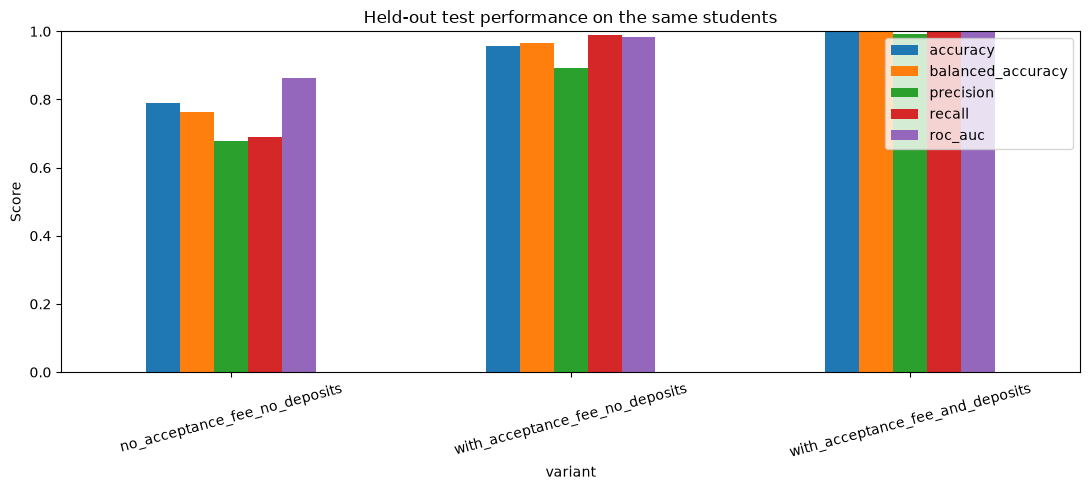

Saved comparison table and chart to c:\Users\Grcar\Documents\datathon\results


In [16]:
comparison = pd.DataFrame([{ "variant": name, "feature_count": len(report["selected_features"]), **{key: value for key, value in report["test_metrics"].items() if key != "confusion_matrix"}} for name, report in reports.items()]).set_index("variant")
comparison.to_csv(output_dir / "model_comparison.csv")
display(comparison)
figure, axis = plt.subplots(figsize=(11, 5))
comparison[["accuracy", "balanced_accuracy", "precision", "recall", "roc_auc"]].plot.bar(ax=axis)
axis.set(ylim=(0, 1), ylabel="Score", title="Held-out test performance on the same students")
axis.tick_params(axis="x", labelrotation=15)
figure.tight_layout()
figure.savefig(output_dir / "model_comparison.png", dpi=180)
display(figure)
plt.close(figure)
print(f"Saved comparison table and chart to {output_dir}")


## 5. Inspect the original 15-feature report
This is the complete metrics file referenced in the request. Rerunning this notebook refreshes it using the fitted model above.


In [17]:
report_path = output_dir / "no_acceptance_fee_no_deposits_metrics.json"
saved_report = json.loads(report_path.read_text(encoding="utf-8"))
display(pd.Series(saved_report, dtype=object).to_frame("saved_report"))
print(f"Complete report: {report_path}")


,saved_report
variant,no_acceptance_fee_no_deposits
original_selected_features,"[visit_mo, campus_visit_tot, visit_yr, visit_d..."
additional_features,[]
model,HistGradientBoostingClassifier
scikit_learn_version,1.9.1
selected_features,"[visit_mo, campus_visit_tot, visit_yr, visit_d..."
target,enrolled
train_rows,55633
test_rows,13908
train_enrollment_rate,0.330775


Complete report: c:\Users\Grcar\Documents\datathon\results\no_acceptance_fee_no_deposits_metrics.json


## 6. Reuse the saved model
This final example reloads the first model and scores a small preview of cleaned test rows with the stored preprocessing and threshold. For new students, use rows cleaned with the same month and category mappings from notebook 01.


In [18]:
artifact = joblib.load(output_dir / "no_acceptance_fee_no_deposits_model.joblib")
preview = splits["test"].head(10).copy()
values = prepare_features(preview, artifact["selected_features"])
with threadpool_limits(limits=2):
    preview_probabilities = artifact["model"].predict_proba(values)[:, 1]
preview_path = output_dir / "reloaded_model_preview_predictions.csv"
save_predictions(preview, preview_probabilities, artifact["threshold"], preview_path, artifact["target"])
display(pd.read_csv(preview_path))
print(f"Saved: {preview_path}")


,row_number,student_id,actual_enrolled,enrollment_probability,predicted_enrolled
0,1,112761,0,0.000264,0
1,2,108208,0,0.000220,0
2,3,47814,0,0.000492,0
3,4,91551,0,0.000369,0
4,5,95105,0,0.000366,0
5,6,106273,0,0.000408,0
6,7,107016,0,0.000295,0
7,8,96524,0,0.000380,0
8,9,108469,0,0.000218,0
9,10,94348,0,0.000230,0


Saved: c:\Users\Grcar\Documents\datathon\results\reloaded_model_preview_predictions.csv
